# What is a Convolution?

## Overview
This notebook explains the fundamental concept of convolution - the core operation that makes CNNs work. We'll visualize how filters slide over images and detect patterns.

## Learning Objectives
- Understand the convolution operation
- See how filters detect patterns
- Learn about local receptive fields and shared weights
- Visualize convolution in action

In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import seaborn as sns

# Set style for better visualizations
plt.style.use('default')
sns.set_palette("husl")

## Concept: The Convolution Operation

Convolution is a mathematical operation where a **filter (kernel)** slides over an **input image** to produce a **feature map**.

### Key Components:
1. **Input**: Original image or feature map
2. **Filter/Kernel**: Small matrix that detects patterns
3. **Output**: Feature map showing where patterns were found

### The Process:
1. Place filter at top-left of image
2. Multiply corresponding elements
3. Sum all products → single output value
4. Slide filter to next position
5. Repeat until entire image is covered

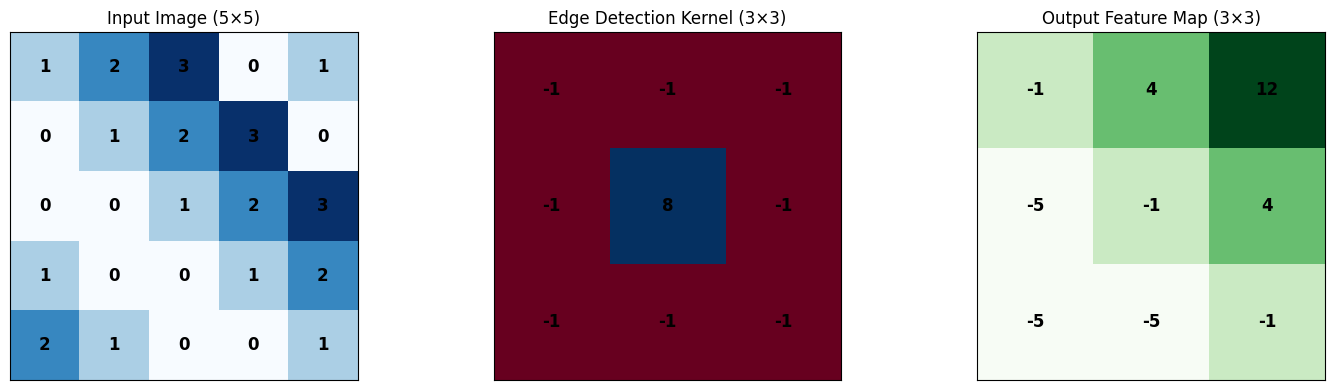

Input shape: (5, 5)
Kernel shape: (3, 3)
Output shape: (3, 3)


In [12]:
# Create a simple example to demonstrate convolution
def manual_convolution_2d(input_img, kernel):
    """Manual implementation of 2D convolution for demonstration"""
    input_h, input_w = input_img.shape
    kernel_h, kernel_w = kernel.shape

    # Output dimensions
    output_h = input_h - kernel_h + 1
    output_w = input_w - kernel_w + 1

    output = np.zeros((output_h, output_w))

    # Slide kernel over input
    for i in range(output_h):
        for j in range(output_w):
            # Extract region
            region = input_img[i:i+kernel_h, j:j+kernel_w]
            # Element-wise multiplication and sum
            output[i, j] = np.sum(region * kernel)

    return output

# Create a simple input image
input_image = np.array([
    [1, 2, 3, 0, 1],
    [0, 1, 2, 3, 0],
    [0, 0, 1, 2, 3],
    [1, 0, 0, 1, 2],
    [2, 1, 0, 0, 1]
])

# Define an edge detection kernel
edge_kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

# Perform convolution
output = manual_convolution_2d(input_image, edge_kernel)

# Visualize the process
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Input image
im1 = axes[0].imshow(input_image, cmap='Blues')
axes[0].set_title('Input Image (5×5)')
for i in range(input_image.shape[0]):
    for j in range(input_image.shape[1]):
        axes[0].text(j, i, str(input_image[i, j]),
                    ha='center', va='center', fontsize=12, fontweight='bold')

# Kernel
im2 = axes[1].imshow(edge_kernel, cmap='RdBu', vmin=-1, vmax=1)
axes[1].set_title('Edge Detection Kernel (3×3)')
for i in range(edge_kernel.shape[0]):
    for j in range(edge_kernel.shape[1]):
        axes[1].text(j, i, str(edge_kernel[i, j]),
                    ha='center', va='center', fontsize=12, fontweight='bold')

# Output
im3 = axes[2].imshow(output, cmap='Greens')
axes[2].set_title('Output Feature Map (3×3)')
for i in range(output.shape[0]):
    for j in range(output.shape[1]):
        axes[2].text(j, i, f'{output[i, j]:.0f}',
                    ha='center', va='center', fontsize=12, fontweight='bold')

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

print(f"Input shape: {input_image.shape}")
print(f"Kernel shape: {edge_kernel.shape}")
print(f"Output shape: {output.shape}")

## Step-by-Step Convolution Process

Step-by-step convolution process:

Step 1: Position (0, 0)


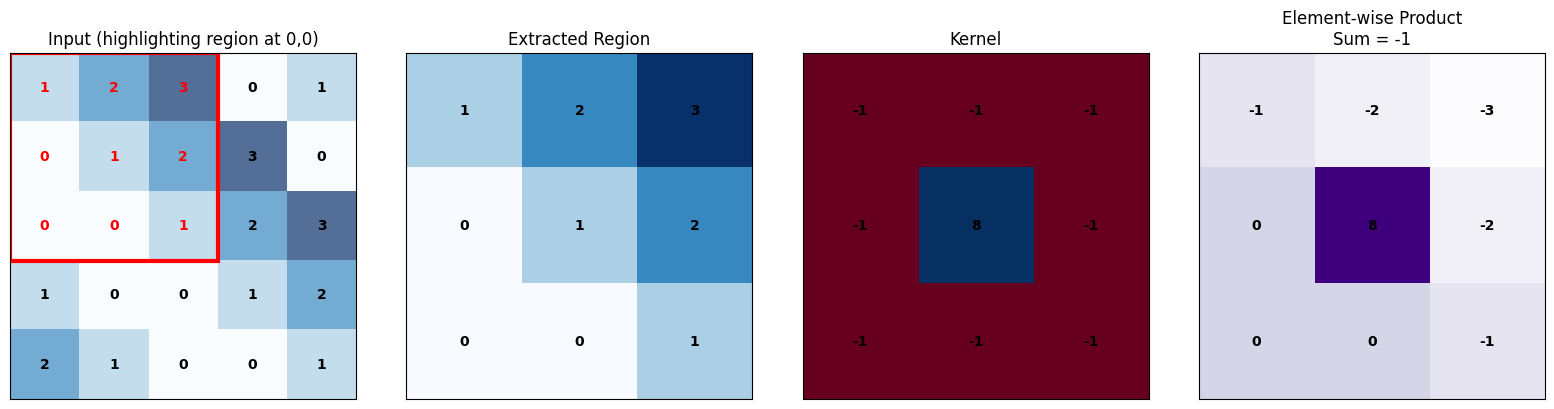

Output value: -1

Step 2: Position (0, 1)


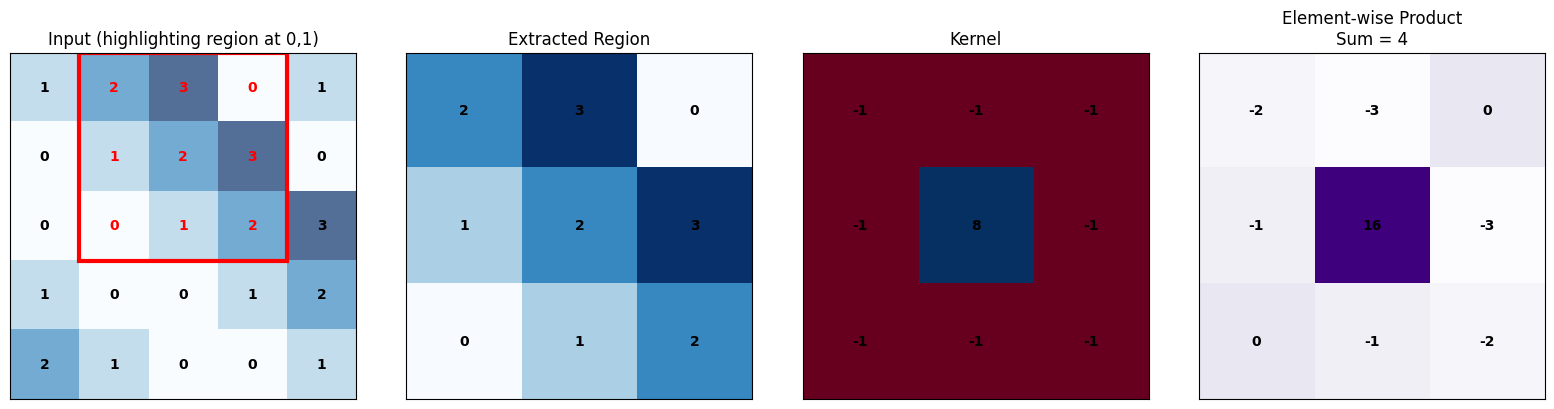

Output value: 4

Step 3: Position (1, 0)


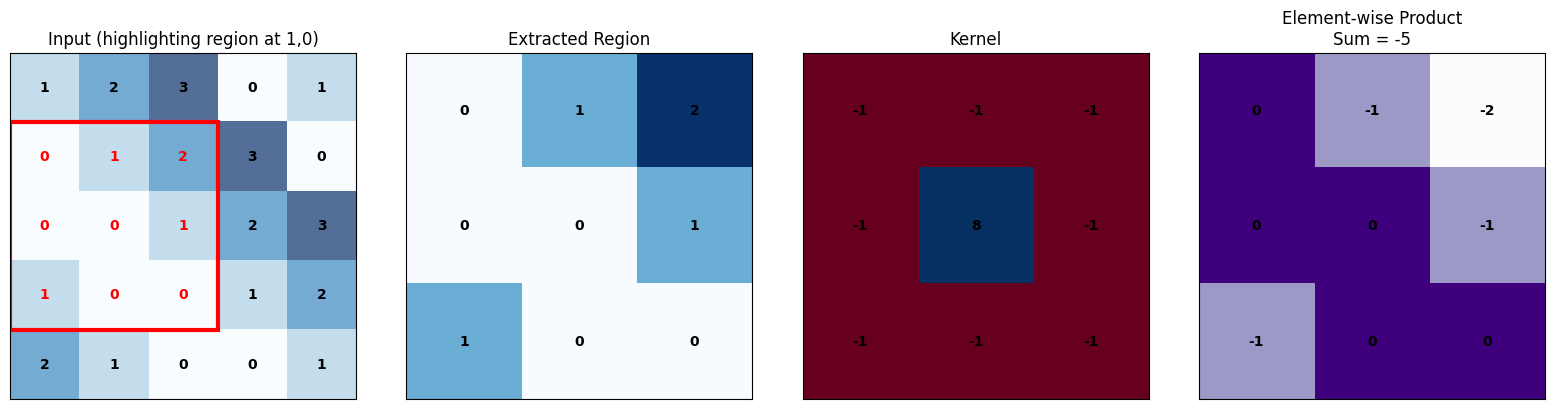

Output value: -5


In [13]:
# Demonstrate step-by-step convolution
def visualize_convolution_step(input_img, kernel, step_i, step_j):
    """Visualize a single step of convolution"""
    kernel_h, kernel_w = kernel.shape

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # 1. Show input with highlighted region
    axes[0].imshow(input_img, cmap='Blues', alpha=0.7)
    axes[0].add_patch(Rectangle((step_j-0.5, step_i-0.5), kernel_w, kernel_h,
                               linewidth=3, edgecolor='red', facecolor='none'))
    axes[0].set_title(f'Input (highlighting region at {step_i},{step_j})')

    # Add numbers
    for i in range(input_img.shape[0]):
        for j in range(input_img.shape[1]):
            color = 'red' if (step_i <= i < step_i+kernel_h and step_j <= j < step_j+kernel_w) else 'black'
            axes[0].text(j, i, str(input_img[i, j]),
                        ha='center', va='center', fontweight='bold', color=color)

    # 2. Show extracted region
    region = input_img[step_i:step_i+kernel_h, step_j:step_j+kernel_w]
    axes[1].imshow(region, cmap='Blues')
    axes[1].set_title('Extracted Region')
    for i in range(region.shape[0]):
        for j in range(region.shape[1]):
            axes[1].text(j, i, str(region[i, j]),
                        ha='center', va='center', fontweight='bold')

    # 3. Show kernel
    axes[2].imshow(kernel, cmap='RdBu', vmin=-1, vmax=1)
    axes[2].set_title('Kernel')
    for i in range(kernel.shape[0]):
        for j in range(kernel.shape[1]):
            axes[2].text(j, i, str(kernel[i, j]),
                        ha='center', va='center', fontweight='bold')

    # 4. Show computation
    product = region * kernel
    result = np.sum(product)

    axes[3].imshow(product, cmap='Purples')
    axes[3].set_title(f'Element-wise Product\nSum = {result:.0f}')
    for i in range(product.shape[0]):
        for j in range(product.shape[1]):
            axes[3].text(j, i, f'{product[i, j]:.0f}',
                        ha='center', va='center', fontweight='bold')

    for ax in axes:
        ax.set_xticks([])
        ax.set_yticks([])

    plt.tight_layout()
    plt.show()

    return result

# Show first few steps
print("Step-by-step convolution process:")
print("=" * 40)

positions = [(0, 0), (0, 1), (1, 0)]
for idx, (i, j) in enumerate(positions):
    print(f"\nStep {idx+1}: Position ({i}, {j})")
    result = visualize_convolution_step(input_image, edge_kernel, i, j)
    print(f"Output value: {result}")

## Where Do Filters Come From? Historical Perspective

### 🕰️ **The Old Days (1960s-1980s): Hand-Crafted Filters**

In the early days of computer vision, **humans designed filters manually** based on mathematical theory and domain knowledge:

#### **Classic Hand-Crafted Filters:**
- **Sobel Filter** (1968): For edge detection
- **Gaussian Filter**: For blur/smoothing
- **Laplacian Filter**: For edge enhancement
- **Gabor Filters**: For texture analysis

#### **Problems with Hand-Crafted Filters:**
- ❌ Limited to what humans could think of
- ❌ Required deep expertise in signal processing
- ❌ Not optimal for specific tasks
- ❌ Couldn't adapt to new data

### 🚀 **Modern Era (1990s-Present): Learned Filters**

With CNNs and backpropagation, we discovered something revolutionary:
**Let the neural network learn the best filters automatically!**

#### **How Modern CNNs Learn Filters:**
1. **Random Initialization**: Start with random filter values
2. **Forward Pass**: Apply filters to images
3. **Calculate Loss**: Compare predictions to true labels
4. **Backpropagation**: Calculate gradients for each filter value
5. **Update Filters**: Adjust filter values to reduce loss
6. **Repeat**: Do this millions of times with different images

#### **Advantages of Learned Filters:**
- ✅ **Task-Specific**: Filters optimize for your exact problem
- ✅ **Data-Driven**: Adapt to patterns in your dataset
- ✅ **Automatic**: No human expertise needed
- ✅ **Hierarchical**: Early layers learn edges, later layers learn complex patterns
- ✅ **Better Performance**: Often much better than hand-crafted filters

## Common Filter Types and Their Effects

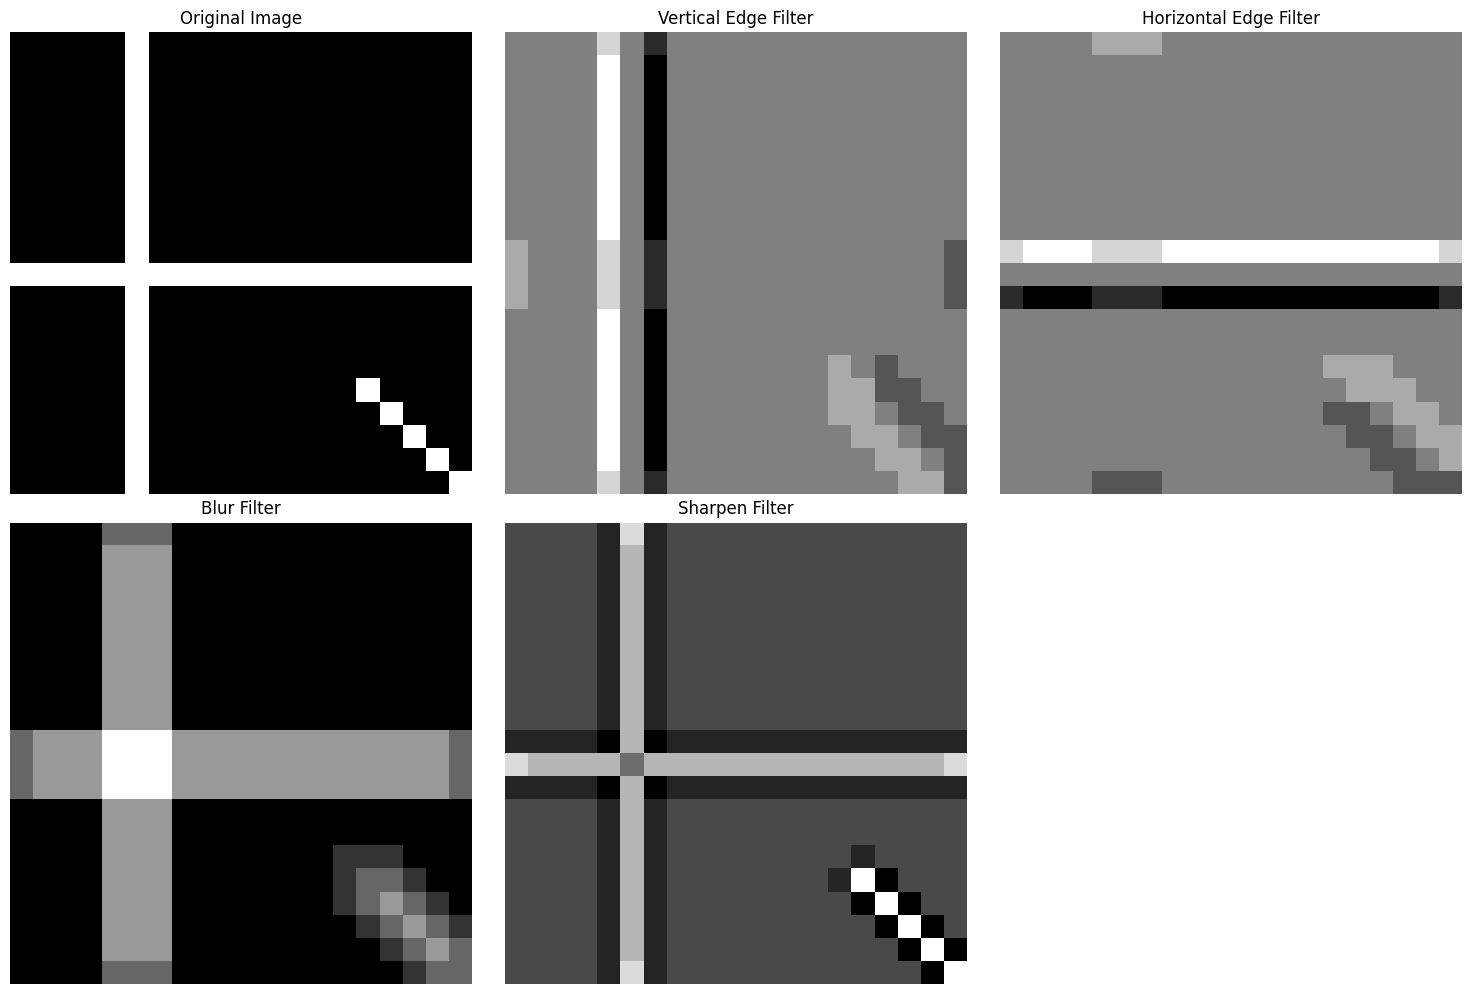

Filter Effects:
- Vertical Edge: Detects vertical lines and edges
- Horizontal Edge: Detects horizontal lines and edges
- Blur: Smooths the image, reduces noise
- Sharpen: Enhances edges and details


In [14]:
# Create a more interesting test image
test_image = np.zeros((20, 20))
# Add vertical line
test_image[:, 5] = 1
# Add horizontal line
test_image[10, :] = 1
# Add diagonal pattern
for i in range(15, 20):
    for j in range(15, 20):
        if i == j:
            test_image[i, j] = 1

# Define different types of filters
filters = {
    'Vertical Edge': np.array([[-1, 0, 1],
                              [-1, 0, 1],
                              [-1, 0, 1]]),

    'Horizontal Edge': np.array([[-1, -1, -1],
                                [ 0,  0,  0],
                                [ 1,  1,  1]]),

    'Blur': np.array([[1, 1, 1],
                     [1, 1, 1],
                     [1, 1, 1]]) / 9,

    'Sharpen': np.array([[ 0, -1,  0],
                        [-1,  5, -1],
                        [ 0, -1,  0]])
}

# Apply each filter
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

# Show original image
axes[0].imshow(test_image, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

# Apply each filter
for idx, (name, kernel) in enumerate(filters.items()):
    # Use PyTorch for convolution
    input_tensor = torch.tensor(test_image).unsqueeze(0).unsqueeze(0).float()
    kernel_tensor = torch.tensor(kernel).unsqueeze(0).unsqueeze(0).float()

    output_tensor = F.conv2d(input_tensor, kernel_tensor, padding=1)
    output = output_tensor.squeeze().numpy()

    axes[idx + 1].imshow(output, cmap='gray')
    axes[idx + 1].set_title(f'{name} Filter')
    axes[idx + 1].axis('off')

# Hide the last subplot
axes[5].axis('off')

plt.tight_layout()
plt.show()

print("Filter Effects:")
print("- Vertical Edge: Detects vertical lines and edges")
print("- Horizontal Edge: Detects horizontal lines and edges")
print("- Blur: Smooths the image, reduces noise")
print("- Sharpen: Enhances edges and details")

## Intuition: Filters "Look For" Patterns

Think of convolution filters as pattern detectors:
- **Edge detectors**: Look for sudden changes in intensity
- **Blob detectors**: Look for circular patterns
- **Line detectors**: Look for linear structures
- **Texture detectors**: Look for repeating patterns

The convolution operation computes how well the filter pattern matches the local image region.

## Summary: Why Convolution Works

### Mathematical Operation:
- Filter slides over image
- Element-wise multiplication and sum
- Produces feature map showing pattern matches

### Key Advantages:
1. **Local Connectivity**: Each output connects to small local region
2. **Parameter Sharing**: Same filter used everywhere
3. **Translation Invariance**: Detects patterns regardless of position
4. **Sparse Connections**: Much fewer parameters than FC layers

### Biological Inspiration:
- Similar to receptive fields in visual cortex
- Neurons respond to specific patterns in their receptive field
- Hierarchical processing: simple → complex features

### Next Steps:
In the next notebook, we'll see how convolution layers are implemented in practice and how they fit into complete CNN architectures.